[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/practical-cheminformatics-course/blob/main/notebooks/11_honest_validation_splits.ipynb)

# 11 · Honest Validation: Random vs Scaffold vs Cluster Splits

*Practical Cheminformatics Course · Hamza Hentabli, Ph.D. · ~50 min*

In a random split, close analogues of every test molecule usually sit in the training set,
so the test score measures *interpolation*. In a real project you predict **new chemical series**.
Structure-aware splits keep whole scaffolds or clusters on one side and give a more honest estimate.

**Learning objectives.** By the end of this notebook you will be able to:

- explain why random splits overestimate performance on new chemistry
- implement scaffold and Butina-cluster splits with scikit-learn group splitters
- measure train-test similarity to diagnose leakage
- report model performance across several seeds and split strategies

In [1]:
# Setup: installs dependencies on Google Colab and locates the course data.
# Running locally? Install requirements.txt once and this cell does nothing extra.
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", 'rdkit', 'scikit-learn'], check=True)
    if not os.path.isdir("practical-cheminformatics-course"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/practical-cheminformatics-course.git"], check=True)
    DATA_DIR = "practical-cheminformatics-course/data"
else:
    DATA_DIR = "../data" if os.path.isdir("../data") else "data"

print("Running on Colab:", IN_COLAB, "| data folder:", DATA_DIR)

Running on Colab: False | data folder: ../data


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem import Draw
from rdkit.Chem.Draw import IPythonConsole
RDLogger.DisableLog("rdApp.*")
from rdkit.Chem import rdFingerprintGenerator
from rdkit.Chem.Scaffolds import MurckoScaffold
from rdkit.ML.Cluster import Butina
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

esol = pd.read_csv(f"{DATA_DIR}/esol_delaney.csv")
mols = [Chem.MolFromSmiles(s) for s in esol["smiles"]]
y = esol["logS"].values
mfpgen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
fps = [mfpgen.GetFingerprint(m) for m in mols]
X = np.array([mfpgen.GetFingerprintAsNumPy(m) for m in mols])
print(X.shape)

(1128, 2048)


## 1. Define the groups: scaffolds and clusters

Each molecule gets a scaffold-group id and a Butina-cluster id. A group-aware splitter then keeps
every molecule of a group entirely in train or entirely in test.

In [3]:
scaffolds = [Chem.MolToSmiles(MurckoScaffold.GetScaffoldForMol(m)) for m in mols]
scaffold_id = pd.factorize(pd.Series(scaffolds))[0]

dists = []
for i in range(1, len(fps)):
    dists.extend(1 - s for s in DataStructs.BulkTanimotoSimilarity(fps[i], fps[:i]))
clusters = Butina.ClusterData(dists, len(fps), 0.6, isDistData=True)
cluster_id = np.empty(len(mols), dtype=int)
for cid, members in enumerate(clusters):
    for i in members:
        cluster_id[i] = cid

print("molecules:", len(mols), "| scaffold groups:", len(set(scaffold_id)), "| Butina clusters:", len(clusters))

molecules: 1128 | scaffold groups: 269 | Butina clusters: 421


## 2. A helper that fits a model and measures leakage

For each split we record the test R2 **and** the median nearest-neighbour Tanimoto similarity from
each test molecule to the training set. High similarity means the test set is "easy".

In [4]:
def nn_similarity(train_idx, test_idx):
    train_fps = [fps[i] for i in train_idx]
    sims = [max(DataStructs.BulkTanimotoSimilarity(fps[i], train_fps)) for i in test_idx]
    return float(np.median(sims))

def run_split(train_idx, test_idx, seed=0):
    rf = RandomForestRegressor(n_estimators=400, random_state=seed, n_jobs=-1)
    rf.fit(X[train_idx], y[train_idx])
    pred = rf.predict(X[test_idx])
    return (r2_score(y[test_idx], pred),
            mean_squared_error(y[test_idx], pred) ** 0.5,
            nn_similarity(train_idx, test_idx))

def random_split(seed):
    return train_test_split(np.arange(len(mols)), test_size=0.2, random_state=seed)

def group_split(groups, seed):
    gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=seed)
    return next(gss.split(X, y, groups=groups))

## 3. Compare the three strategies across 5 seeds

In [5]:
rows = []
for seed in range(5):
    for name, (tr, te) in [
        ("random", random_split(seed)),
        ("scaffold", group_split(scaffold_id, seed)),
        ("cluster (Butina)", group_split(cluster_id, seed)),
    ]:
        r2, rmse, sim = run_split(tr, te, seed)
        rows.append({"split": name, "seed": seed, "R2": r2, "RMSE": rmse, "test-train NN sim": sim})
res = pd.DataFrame(rows)
summary = res.groupby("split").agg(
    R2_mean=("R2", "mean"), R2_sd=("R2", "std"),
    RMSE_mean=("RMSE", "mean"), NN_sim_mean=("test-train NN sim", "mean")).round(3)
summary = summary.reindex(["random", "scaffold", "cluster (Butina)"])
summary

,R2_mean,R2_sd,RMSE_mean,NN_sim_mean
split,,,,
random,0.680,0.041,1.184,0.556
scaffold,0.050,0.433,1.861,0.421
cluster (Butina),0.516,0.067,1.389,0.400


The random split reports the highest R2 and the highest test-train similarity. The scaffold and
cluster splits are harder *and* more realistic. The gap between them is the **optimism** of a random split:
roughly how much you would overstate performance by validating the easy way.

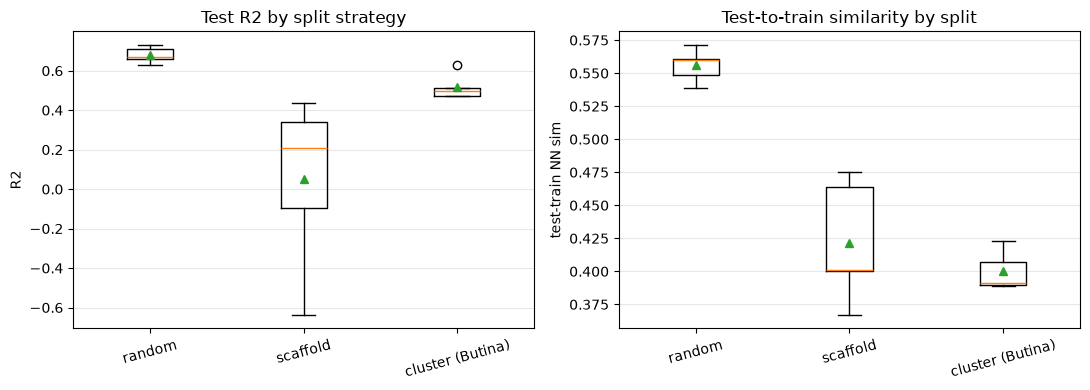

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True)
order = ["random", "scaffold", "cluster (Butina)"]
colors = ["tab:blue", "tab:orange", "tab:green"]
for ax, col, title in zip(axes, ["R2", "test-train NN sim"],
                          ["Test R2 by split strategy", "Test-to-train similarity by split"]):
    data = [res[res.split == s][col].values for s in order]
    ax.boxplot(data, showmeans=True)
    ax.set_xticks(range(1, len(order) + 1))
    ax.set_xticklabels(order, rotation=15)
    ax.set_ylabel(col); ax.set_title(title); ax.grid(alpha=0.3, axis="y")
plt.tight_layout(); plt.show()

## 4. Why similarity drives the score

Pool all five seeds of the scaffold split and bin test molecules by how similar they are to the
training set. Accuracy falls as similarity falls, which is exactly why the split strategy matters.

In [7]:
tr, te = group_split(scaffold_id, 0)
rf = RandomForestRegressor(n_estimators=400, random_state=0, n_jobs=-1).fit(X[tr], y[tr])
pred = rf.predict(X[te])
train_fps = [fps[i] for i in tr]
sim = np.array([max(DataStructs.BulkTanimotoSimilarity(fps[i], train_fps)) for i in te])
abs_err = np.abs(pred - y[te])

bins = pd.cut(sim, [0, 0.2, 0.3, 0.4, 0.5, 1.0])
pd.DataFrame({"nearest-neighbour Tanimoto": bins, "abs error": abs_err}).groupby(
    "nearest-neighbour Tanimoto", observed=True)["abs error"].agg(["size", "mean"]).round(3)

,size,mean
nearest-neighbour Tanimoto,,
"(0.0, 0.2]",2,0.811
"(0.2, 0.3]",10,1.125
"(0.3, 0.4]",15,0.770
"(0.4, 0.5]",33,1.248
"(0.5, 1.0]",38,1.057


## 5. The takeaway, as a single number

In [8]:
gap = summary.loc["random", "R2_mean"] - summary.loc["scaffold", "R2_mean"]
print(f"Random split mean R2:   {summary.loc['random', 'R2_mean']:.3f}")
print(f"Scaffold split mean R2: {summary.loc['scaffold', 'R2_mean']:.3f}")
print(f"Optimism of the random split: {gap:+.3f} R2 units")

Random split mean R2:   0.680
Scaffold split mean R2: 0.050
Optimism of the random split: +0.630 R2 units


> This is exactly what [**qsar-split-bench**](https://github.com/hentablihamza/qsar-split-bench)
> automates: it benchmarks random, scaffold, Butina-cluster, and time splits side by side and reports
> the optimism gap and train-test similarity for any dataset, in one command.

### ✏️ Exercise 1

Repeat the random vs scaffold comparison with a **50/50** split (`test_size=0.5`). Does the optimism gap grow or shrink?

In [9]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
def run(groups, strat, seed):
    if strat == "random":
        tr, te = train_test_split(np.arange(len(mols)), test_size=0.5, random_state=seed)
    else:
        tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=seed).split(X, y, groups=groups))
    return run_split(tr, te, seed)[0]
r = np.mean([run(None, "random", s) for s in range(5)])
sc = np.mean([run(scaffold_id, "scaffold", s) for s in range(5)])
print(f"random R2 {r:.3f} | scaffold R2 {sc:.3f} | gap {r - sc:+.3f}")
```

</details>

### ✏️ Exercise 2

How many scaffold groups are singletons (one molecule), and what fraction of all molecules do they represent? This is why scaffold splits are hard.

In [10]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
vc = pd.Series(scaffold_id).value_counts()
singleton_groups = (vc == 1).sum()
print(singleton_groups, "singleton scaffolds covering",
      f"{(vc[vc == 1].sum() / len(mols)):.1%} of molecules")
```

</details>

### ✏️ Exercise 3

Using the seed-0 scaffold split, what is the maximum test-to-train Tanimoto similarity? Draw the test molecule most similar to the training set and its nearest training neighbour.

In [11]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
tr, te = group_split(scaffold_id, 0)
train_fps = [fps[i] for i in tr]
best_sim, best_te, best_tr = 0, None, None
for i in te:
    sims = DataStructs.BulkTanimotoSimilarity(fps[i], train_fps)
    j = int(np.argmax(sims))
    if sims[j] > best_sim:
        best_sim, best_te, best_tr = sims[j], i, tr[j]
print("max test-train Tanimoto:", round(best_sim, 3))
Draw.MolsToGridImage([mols[best_te], mols[best_tr]], legends=["test molecule", "nearest train neighbour"],
                     subImgSize=(300, 230))
```

</details>

## Key takeaways

- A random split answers "can the model interpolate?"; a scaffold/cluster split answers "can it generalize to new chemistry?".
- Always report the split strategy, and ideally the test-train similarity, next to any QSAR metric.
- The optimism gap is often large. Validate the way you intend to deploy.

**Next:** [12 · Virtual screening and enrichment](12_virtual_screening_enrichment.ipynb).